# *Análise exploratória de Monitoramento de Fauna*

### •Importação das Bibliotecas

In [1]:
import pandas as pd
import numpy as np
from datetime import time
#%pip install matplotlib
#%pip install plotly
#%pip install jinja2
import matplotlib.pyplot as plt
import plotly as py
from numpy import var
import random

### •Configuração para mostrar as linhas e colunas do arquivo

In [2]:
desired_width = 320
np.set_printoptions(linewidth=desired_width)
pd.set_option('display.width', desired_width)
pd.set_option('display.max_columns',20)
pd.set_option('display.max_rows', None)

### •Importação do Dataset

In [3]:
dt = pd.read_json("dataset_monitoramento_fauna.json")
display(dt.head().style.hide(axis='index'))#esconde o index já que existe a coluna de ID

id_registro,id_camera,data_hora_inicio,duracao_segundos,especie,grupo,individuos,temperatura_c,umidade_pct
1,CAM01,2026-05-01 00:04:00,25,Ema,Ave,3,19.3 °C,81.5%
2,CAM08,2026-05-01 00:18:00,9,Rã-manteiga,Anfíbio,3,16.6 °C,88.8%
3,CAM08,2026-05-01 00:32:00,6,Tatu-canastra,Mamífero,1,16.5 °C,96.3%
4,CAM12,2026-05-01 00:37:00,13,Rã-manteiga,Anfíbio,2,19.2 °C,92.1%
5,CAM03,2026-05-01 00:39:00,25,Tamanduá-bandeira,Mamífero,1,20.5 °C,82.6%


### •Informações gerais do Dataset

In [4]:
dt.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   id_registro       5000 non-null   int64
 1   id_camera         5000 non-null   str  
 2   data_hora_inicio  5000 non-null   str  
 3   duracao_segundos  5000 non-null   int64
 4   especie           5000 non-null   str  
 5   grupo             5000 non-null   str  
 6   individuos        5000 non-null   int64
 7   temperatura_c     4753 non-null   str  
 8   umidade_pct       4825 non-null   str  
dtypes: int64(3), str(6)
memory usage: 351.7 KB


### •Mostrar primeiras e últimas linhas

In [5]:
display(pd.concat([dt.head(10), dt.iloc[-8:]]).style.hide(axis='index'))

id_registro,id_camera,data_hora_inicio,duracao_segundos,especie,grupo,individuos,temperatura_c,umidade_pct
1,CAM01,2026-05-01 00:04:00,25,Ema,Ave,3,19.3 °C,81.5%
2,CAM08,2026-05-01 00:18:00,9,Rã-manteiga,Anfíbio,3,16.6 °C,88.8%
3,CAM08,2026-05-01 00:32:00,6,Tatu-canastra,Mamífero,1,16.5 °C,96.3%
4,CAM12,2026-05-01 00:37:00,13,Rã-manteiga,Anfíbio,2,19.2 °C,92.1%
5,CAM03,2026-05-01 00:39:00,25,Tamanduá-bandeira,Mamífero,1,20.5 °C,82.6%
6,CAM08,2026-05-01 00:47:00,19,Sapo-cururu,Anfíbio,3,18.2 °C,90.9%
7,CAM12,2026-05-01 00:48:00,46,Quati,Mamífero,4,16.9 °C,95.5%
8,CAM05,2026-05-01 00:49:00,35,Perereca-verde,Anfíbio,2,14.6 °C,94.1%
9,CAM04,2026-05-01 00:49:00,46,Sapo-cururu,Anfíbio,3,20.6 °C,92.8%
10,CAM12,2026-05-01 00:51:00,31,Capivara,Mamífero,6,20.8 °C,97.1%


### •Mostrar colunas com linhas em branco

In [6]:
colunas = dt.isnull().any()
print(colunas)

display(dt.columns[colunas])

id_registro         False
id_camera           False
data_hora_inicio    False
duracao_segundos    False
especie             False
grupo               False
individuos          False
temperatura_c        True
umidade_pct          True
dtype: bool


Index(['temperatura_c', 'umidade_pct'], dtype='str')

### •Qtd de linhas em branco

In [7]:
linhas = dt.columns[colunas]
dt[linhas].isnull().sum()


temperatura_c    247
umidade_pct      175
dtype: int64

### •Mostrar qtd de registros de cada espécie

In [8]:
dt[["id_registro","especie"]].groupby("especie").count().sort_values(by="id_registro",ascending=False)

,id_registro
especie,
Capivara,731
Sapo-cururu,564
Ema,551
Seriema,506
Lobo-guará,425
Tamanduá-bandeira,401
Perereca-verde,389
Quati,378
Rã-manteiga,317


### •Mostrar qtd de registros de cada Grupo

In [9]:
dt[["id_registro","grupo"]].groupby("grupo").count().sort_values(by="id_registro",ascending=False)

,id_registro
grupo,
Mamífero,2673
Anfíbio,1270
Ave,1057


### •Mostrar espécies únicas

In [10]:
dt.especie.unique()


<StringArray>
['Ema', 'Rã-manteiga', 'Tatu-canastra', 'Tamanduá-bandeira', 'Sapo-cururu', 'Quati', 'Perereca-verde', 'Capivara', 'Veado-campeiro', 'Lobo-guará', 'Seriema', 'Onça-pintada', 'Cervo-do-pantanal']
Length: 13, dtype: str

### •Mostrar qtd de registros por câmera

In [11]:
dt.id_camera.value_counts().reset_index()

,id_camera,count
0,CAM09,523
1,CAM12,504
2,CAM10,474
3,CAM02,471
4,CAM04,442
5,CAM08,418
6,CAM06,400
7,CAM01,394
8,CAM05,377
9,CAM07,364


### •Mostrar qtd de registros por câmera e epécie

In [12]:
resultado = (
    dt.value_counts(["id_camera", "especie"])
    .reset_index(name="Qtd")
    .sort_values(
        by=["id_camera", "Qtd"],
        ascending=[True, False]
    ).reset_index(drop=True)
)

resultado.head(30)

,id_camera,especie,Qtd
0,CAM01,Ema,80
1,CAM01,Seriema,76
2,CAM01,Lobo-guará,66
3,CAM01,Veado-campeiro,53
4,CAM01,Tamanduá-bandeira,35
5,CAM01,Tatu-canastra,32
6,CAM01,Sapo-cururu,14
7,CAM01,Quati,14
8,CAM01,Capivara,9
9,CAM01,Cervo-do-pantanal,7


### •Mostrar qual epécie foi mais registrada

In [13]:
Qtd = (
    dt.value_counts(["especie"])
    .reset_index(name="Qtd")
    .sort_values(
        by=["Qtd"],
        ascending=[False]
    ).reset_index(drop=True)
)

Qtd

,especie,Qtd
0,Capivara,731
1,Sapo-cururu,564
2,Ema,551
3,Seriema,506
4,Lobo-guará,425
5,Tamanduá-bandeira,401
6,Perereca-verde,389
7,Quati,378
8,Rã-manteiga,317
9,Veado-campeiro,292


## Desafio 1 - Animais solitários ou em grupo?

Durante o monitoramento, os pesquisadores querem entender como a **capivara** costuma ser registrada pelas câmeras.

**Pergunta:**

> **Qual é o número médio de indivíduos por registro de capivara? A maior parte dos registros envolve indivíduos isolados ou grupos?**

### •Mostrar registros da Capivara

In [14]:
capi = dt[(dt.especie=='Capivara')]
capi.head(10)


,id_registro,id_camera,data_hora_inicio,duracao_segundos,especie,grupo,individuos,temperatura_c,umidade_pct
9,10,CAM12,2026-05-01 00:51:00,31,Capivara,Mamífero,6,20.8 °C,97.1%
22,23,CAM12,2026-05-01 03:06:00,37,Capivara,Mamífero,5,15.7 °C,98.6%
37,38,CAM09,2026-05-01 05:11:00,30,Capivara,Mamífero,11,18.3 °C,96.3%
45,46,CAM10,2026-05-01 06:04:00,4,Capivara,Mamífero,7,18.5 °C,88.0%
47,48,CAM12,2026-05-01 06:08:00,24,Capivara,Mamífero,3,17.7 °C,99.0%
49,50,CAM05,2026-05-01 06:31:00,53,Capivara,Mamífero,5,21.0 °C,91.7%
50,51,CAM09,2026-05-01 06:44:00,11,Capivara,Mamífero,6,18.2 °C,97.1%
55,56,CAM07,2026-05-01 07:13:00,16,Capivara,Mamífero,6,19.6 °C,84.1%
56,57,CAM07,2026-05-01 07:24:00,18,Capivara,Mamífero,6,17.5 °C,85.2%
62,63,CAM10,2026-05-01 08:01:00,6,Capivara,Mamífero,10,21.9 °C,94.9%


### *Número médio de indivíduos por registro:*

In [15]:
media = round(dt[(dt.especie=='Capivara')].individuos.mean(),2)
print("Média de indivíduos =", media)

Média de indivíduos = 5.95


### *Mostrar os registros de indivíduos solitários:*

In [16]:
capi_so_qtd = dt[(dt.especie=='Capivara') & 
                 (dt.individuos==1)
]['id_registro'].count()
capi_so = dt[(dt.especie=='Capivara') & 
             (dt.individuos==1)
][
    ['id_registro','individuos','data_hora_inicio']
].reset_index(drop=True)
print("Registros de Inivíduos Solitários =", capi_so_qtd)
display(capi_so)



Registros de Inivíduos Solitários = 6


,id_registro,individuos,data_hora_inicio
0,1974,1,2026-05-12 18:15:00
1,2195,1,2026-05-14 02:40:00
2,3973,1,2026-05-24 17:04:00
3,4364,1,2026-05-27 03:10:00
4,4557,1,2026-05-28 07:20:00
5,4955,1,2026-05-30 16:50:00


### *Mostrar os registros em grupo:*

In [17]:
capi_grp_qtd = dt[
    (dt.especie=='Capivara') & 
    (dt.individuos>1)
][
    'id_registro'].count()

capi_grp = dt[
    (dt.especie=='Capivara') & 
    (dt.individuos>1)
][
        ['id_registro','individuos','data_hora_inicio']
].sort_values(
    by='individuos', 
    ascending=False
).reset_index(drop=True)
print("Registros de Indivíduos em Grupos =", capi_grp_qtd)
display(capi_grp.head())


Registros de Indivíduos em Grupos = 725


,id_registro,individuos,data_hora_inicio
0,1068,14,2026-05-07 10:58:00
1,1648,14,2026-05-10 16:36:00
2,634,13,2026-05-04 19:31:00
3,936,13,2026-05-06 17:33:00
4,4943,13,2026-05-30 15:16:00


### Quantidade de Grupos encontrados

In [18]:
grupos = capi_grp['individuos'].value_counts().sort_index().reset_index()
grupos.columns = ['Individuos', 'Qtd_Registros']
display(grupos)

print("Total de grupos:", len(grupos))


,Individuos,Qtd_Registros
0,2,23
1,3,63
2,4,100
3,5,129
4,6,128
5,7,120
6,8,79
7,9,40
8,10,23
9,11,10


Total de grupos: 13


## Desafio 2 - Quando a fauna está mais ativa?

Depois de entender como os registros se distribuem entre as espécies, a equipe quer investigar **quando** os animais são mais frequentemente registrados.

**Pergunta:**

> **Em quais períodos do dia há mais registros de animais? Escolha três espécies e compare seus horários de maior ocorrência.**

### •Separar a coluna data_hora_inicio em Data e Hora

In [19]:
dt[['Data','Hora']] = dt['data_hora_inicio'].str.split(' ',n=1, expand=True)
dt['Hora'] = pd.to_datetime(dt['Hora'],format='%H:%M:%S').dt.time
dt.head()

,id_registro,id_camera,data_hora_inicio,duracao_segundos,especie,grupo,individuos,temperatura_c,umidade_pct,Data,Hora
0,1,CAM01,2026-05-01 00:04:00,25,Ema,Ave,3,19.3 °C,81.5%,2026-05-01,00:04:00
1,2,CAM08,2026-05-01 00:18:00,9,Rã-manteiga,Anfíbio,3,16.6 °C,88.8%,2026-05-01,00:18:00
2,3,CAM08,2026-05-01 00:32:00,6,Tatu-canastra,Mamífero,1,16.5 °C,96.3%,2026-05-01,00:32:00
3,4,CAM12,2026-05-01 00:37:00,13,Rã-manteiga,Anfíbio,2,19.2 °C,92.1%,2026-05-01,00:37:00
4,5,CAM03,2026-05-01 00:39:00,25,Tamanduá-bandeira,Mamífero,1,20.5 °C,82.6%,2026-05-01,00:39:00


### •Criação de uma coluna nova chamada Periodo, para facilitar a análise de acordo com o período do dia.

In [20]:
dt['Periodo'] = 'Manhã'

dt.loc[dt['Hora'].between(time(0, 0), time(5, 0)),'Periodo'] = 'Madrugada'
dt.loc[dt['Hora'].between(time(12, 0), time(18, 0)),'Periodo'] = 'Tarde'
dt.loc[dt['Hora'].between(time(19, 0), time(23, 0)),'Periodo'] = 'Noite'

dt.head()

,id_registro,id_camera,data_hora_inicio,duracao_segundos,especie,grupo,individuos,temperatura_c,umidade_pct,Data,Hora,Periodo
0,1,CAM01,2026-05-01 00:04:00,25,Ema,Ave,3,19.3 °C,81.5%,2026-05-01,00:04:00,Madrugada
1,2,CAM08,2026-05-01 00:18:00,9,Rã-manteiga,Anfíbio,3,16.6 °C,88.8%,2026-05-01,00:18:00,Madrugada
2,3,CAM08,2026-05-01 00:32:00,6,Tatu-canastra,Mamífero,1,16.5 °C,96.3%,2026-05-01,00:32:00,Madrugada
3,4,CAM12,2026-05-01 00:37:00,13,Rã-manteiga,Anfíbio,2,19.2 °C,92.1%,2026-05-01,00:37:00,Madrugada
4,5,CAM03,2026-05-01 00:39:00,25,Tamanduá-bandeira,Mamífero,1,20.5 °C,82.6%,2026-05-01,00:39:00,Madrugada


### •Análise de Períodos do Dia

In [21]:
dt[["id_registro","Periodo"]].groupby("Periodo").count().sort_values(by="id_registro",ascending=False)

,id_registro
Periodo,
Manhã,2098
Tarde,1322
Madrugada,846
Noite,734


### •Gráfico simples de qtd de registros por período

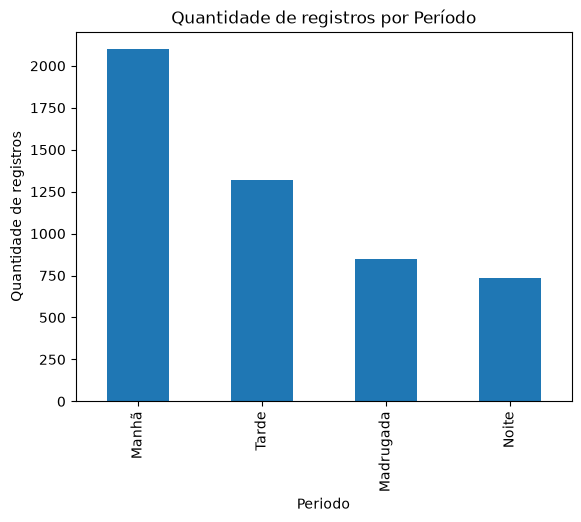

In [22]:
qtd_especies = dt.groupby('Periodo')['id_registro'].count().sort_values(ascending=False)
qtd_especies.plot(kind='bar')

plt.xlabel('Periodo')
plt.ylabel('Quantidade de registros')
plt.title('Quantidade de registros por Período')

plt.show()

### •Gráfico mais elaborado de qtd de registros por período

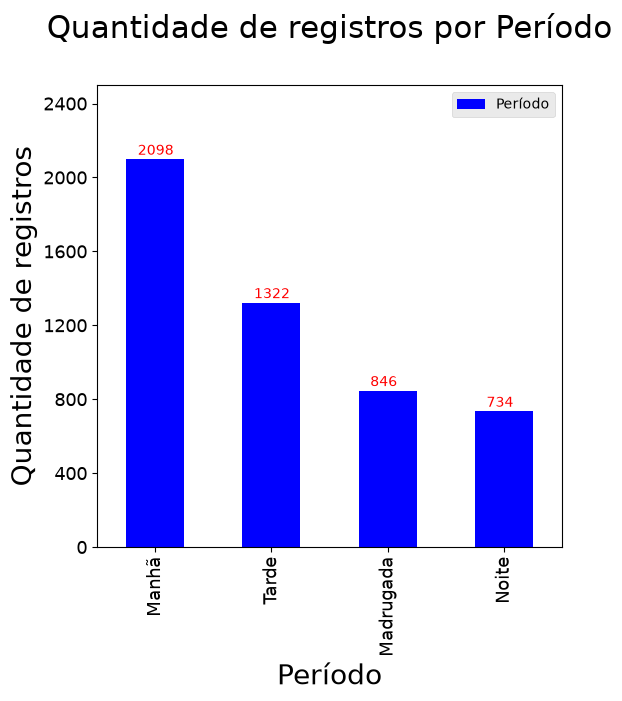

In [23]:
periodo = dt['Periodo'].value_counts()

grf = periodo.plot(
    kind='bar',
    rot=90, 
    figsize=(6,6),
    color='b',
    fontsize=13,
    label='Período'
    )
grf.set_title('Quantidade de registros por Período\n', fontsize=22, color='black')
grf.set_ylabel('Quantidade de registros', fontsize=20)
grf.set_xlabel('Período', fontsize=20)
grf.set_yticks([0,400,800,1200,1600,2000,2400])
grf.set_ylim((0,2500))

totals = []
total = sum(totals)
for i in grf.patches:
    grf.text(
        i.get_x() + 0.1, 
        i.get_height()+25,
        i.get_height(), 
        color='red'
    )
plt.style.use('ggplot')
plt.legend()
plt.show()

In [24]:
dt.especie.value_counts()#.plot(kind='bar', figsize=(10,6), color='g')

especie
Capivara             731
Sapo-cururu          564
Ema                  551
Seriema              506
Lobo-guará           425
Tamanduá-bandeira    401
Perereca-verde       389
Quati                378
Rã-manteiga          317
Veado-campeiro       292
Tatu-canastra        273
Cervo-do-pantanal    153
Onça-pintada          20
Name: count, dtype: int64

### •Análise de período por espécie

In [25]:
especies = dt[
    dt.especie.isin(['Perereca-verde', 'Ema', 'Onça-pintada'])
][
    ["especie","Periodo"]
].groupby(['especie', 'Periodo']).size().reset_index(name='Qtd').sort_values(
    by=['especie', 'Qtd'], ascending=False).style.hide(axis='index')
especies

#display(especies.style.hide(axis='index'))

especie,Periodo,Qtd
Perereca-verde,Noite,127
Perereca-verde,Manhã,120
Perereca-verde,Madrugada,111
Perereca-verde,Tarde,31
Onça-pintada,Manhã,7
Onça-pintada,Madrugada,6
Onça-pintada,Noite,6
Onça-pintada,Tarde,1
Ema,Manhã,243
Ema,Tarde,230


### •Gráfico comparativo de 3 espécies por períodos

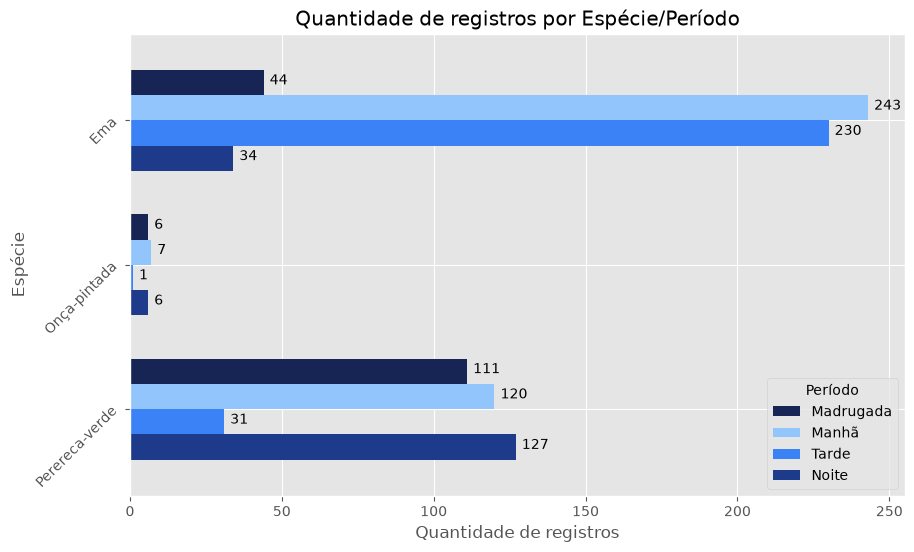

In [26]:
periodo_especie = dt[
    dt.especie.isin(['Perereca-verde', 'Ema', 'Onça-pintada'])
].groupby(
    ['Periodo', 'especie']
).size().reset_index(name='Qtd'
).pivot(
    index='especie',
    columns='Periodo',
    values='Qtd'
)
periodo_especie = periodo_especie[['Madrugada','Manhã', 'Tarde', 'Noite']]

ax = periodo_especie.plot(
    kind='barh',
    figsize=(10, 6),
    color=['#172554', '#93C5FD', '#3B82F6', '#1E3A8A'],
    width=0.7
)

ax.invert_yaxis()

totals = []
for i in ax.patches:
    totals.append(i.get_width())
total = sum(totals)
for i in ax.patches:
    ax.text(
        i.get_width()+2, 
        i.get_y()+0.1,
        i.get_width(),
        fontsize=10,
        color='black'
    )

plt.title('Quantidade de registros por Espécie/Período')
plt.xlabel('Quantidade de registros')
plt.ylabel('Espécie')
plt.yticks(rotation=45)
plt.legend(title='Período')
plt.show()

### •Gráfico comparativo de 3 espécies aleatórias por períodos

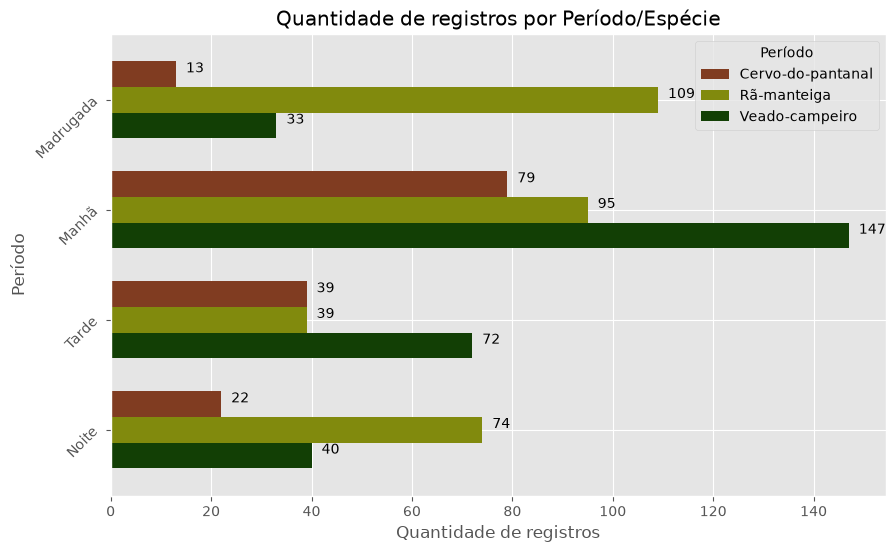

In [27]:
esp_aleat = random.sample(dt['especie'].unique().tolist(), 3)

periodo_especie = dt[
    dt.especie.isin(esp_aleat)
].groupby(
    ['Periodo', 'especie']
).size().reset_index(name='Qtd'
).pivot(
    index='Periodo',
    columns='especie',
    values='Qtd'
)
periodo_especie = periodo_especie.reindex(['Madrugada', 'Manhã', 'Tarde', 'Noite'])

ax = periodo_especie.plot(
    kind='barh',
    figsize=(10, 6),
    color=["#803C21", "#818A0D", "#123F05"],
    width=0.7
)

ax.invert_yaxis()

totals = []
for i in ax.patches:
    totals.append(i.get_width())
total = sum(totals)
for i in ax.patches:
    ax.text(
        i.get_width()+2, 
        i.get_y()+0.1,
        i.get_width(),
        fontsize=10,
        color='black'
    )

plt.title('Quantidade de registros por Período/Espécie')
plt.xlabel('Quantidade de registros')
plt.ylabel('Período')
plt.yticks(rotation=45)
plt.legend(title='Período')
plt.show()

## Desafio 3 - Vale a pena procurar anfíbios em períodos mais úmidos?

A equipe de campo está planejando uma rotina de monitoramento de anfíbios e quer saber se a umidade pode ajudar a definir os melhores momentos para realizar esse trabalho.

**Pergunta:**

> **Os anfíbios são registrados com maior frequência quando a umidade é mais alta? Compare a quantidade de registros em diferentes níveis de umidade e apresente sua conclusão.**

### •Qtd de registros por Umidade ordenado por registro

In [28]:
anfibios = dt[["umidade_pct","id_registro"]].groupby("umidade_pct").count().sort_values(by="id_registro",ascending=False)
anfibios.head(20)

,id_registro
umidade_pct,
99.0%,172
70.0%,30
64.0%,23
83.1%,19
79.8%,19
76.9%,19
74.3%,19
82.2%,19
68.5%,19


### •Qtd de registros por Umidade ordenado por Umidade

In [29]:
anfibios = dt[["id_registro","umidade_pct"]].groupby(["umidade_pct"]).count().sort_values(by="umidade_pct",ascending=False)
anfibios.head(30)

,id_registro
umidade_pct,
99.0%,172
98.9%,7
98.8%,6
98.7%,5
98.6%,4
98.5%,3
98.4%,6
98.3%,2
98.2%,7


### •Qtd de registros por Umidade e Temperatura


In [30]:
anfibios = dt[[
    "id_registro",                
    "umidade_pct",                
    "temperatura_c"]].groupby([                   
        "umidade_pct",                    
        "temperatura_c"                    
        ]).count().sort_values(by="id_registro",ascending=False) 
anfibios.head(40)

id_registro
umidade_pct temperatura_c             
99.0%       18.4 °C                  9
            17.6 °C                  8
            16.7 °C                  7
            16.8 °C                  7
            17.2 °C                  7
            17.5 °C                  7
            16.1 °C                  5
            17.3 °C                  5
            15.7 °C                  5
            16.5 °C                  5
            17.8 °C                  5
            18.3 °C                  5
            15.8 °C                  4
            16.6 °C                  4
            17.4 °C                  4
            17.7 °C                  4
            18.2 °C                  4
            16.3 °C                  3
            16.4 °C                  3
68.5%       27.1 °C                  3
71.3%       28.0 °C                  3
70.0%       27.1 °C                  3
65.1%       27.9 °C                  3
99.0%       16.9 °C                  3
            17.0 °C                  3
66.4%       27.3 °C                  3
73.3%       24.3 °C                  3
77.9%       23.3 °C                  3
80.8%       22.0 °C                  3
83.4%       19.7 °C                  3
99.0%       20.1 °C                  3
89.0%       18.4 °C                  3
99.0%       15.0 °C                  3
            16.2 °C                  3
            18.8 °C                  3
            19.1 °C                  3
            19.4 °C                  3
72.8%       24.0 °C                  2
62.2%       26.2 °C                  2
65.9%       26.8 °C                  2

### •Qtd de registros por Umidade e Temperatura ordenado por umidade


In [31]:
anfibios = (
    dt[[
        "id_registro", 
        "umidade_pct", 
        "temperatura_c"]]
        .assign(
        umidade_pct=lambda x: pd.to_numeric(
            x["umidade_pct"].str.replace("%", "", regex=False),
            errors="coerce"
        ).round().astype("Int64")
    )
    .groupby(
        ["umidade_pct", 
         "temperatura_c"
        ])
    .count()
    .sort_values(by="umidade_pct", ascending=False)
)

anfibios.head(30)

id_registro
umidade_pct temperatura_c             
99          17.6 °C                 10
            19.0 °C                  3
            18.9 °C                  2
            18.8 °C                  3
            18.7 °C                  1
            18.5 °C                  2
            18.4 °C                 10
            18.3 °C                  5
            18.2 °C                  5
            18.1 °C                  1
            18.0 °C                  2
            17.9 °C                  3
            17.8 °C                  6
            21.5 °C                  1
            21.3 °C                  1
            20.8 °C                  1
            20.7 °C                  1
            20.3 °C                  1
            20.2 °C                  1
            20.1 °C                  4
            20.0 °C                  3
            19.9 °C                  1
            19.7 °C                  1
            19.6 °C                  1
            19.5 °C                  1
            19.4 °C                  3
            19.3 °C                  2
            19.1 °C                  3
            17.7 °C                  4
            15.9 °C                  1

In [32]:
anfibios = (
    dt[[
        "id_registro", 
        "umidade_pct", 
        "temperatura_c"]]
        .assign(
        umidade_pct=lambda x: pd.to_numeric(
            x["umidade_pct"].str.replace("%", "", regex=False),
            errors="coerce"
        ).round().astype("Int64")
    )
    .groupby(["umidade_pct", "temperatura_c"])
    .count()
    .sort_values(by="umidade_pct", ascending=False)
)

anfibios.head(50)

id_registro
umidade_pct temperatura_c             
99          17.6 °C                 10
            19.0 °C                  3
            18.9 °C                  2
            18.8 °C                  3
            18.7 °C                  1
            18.5 °C                  2
            18.4 °C                 10
            18.3 °C                  5
            18.2 °C                  5
            18.1 °C                  1
            18.0 °C                  2
            17.9 °C                  3
            17.8 °C                  6
            21.5 °C                  1
            21.3 °C                  1
            20.8 °C                  1
            20.7 °C                  1
            20.3 °C                  1
            20.2 °C                  1
            20.1 °C                  4
            20.0 °C                  3
            19.9 °C                  1
            19.7 °C                  1
            19.6 °C                  1
            19.5 °C                  1
            19.4 °C                  3
            19.3 °C                  2
            19.1 °C                  3
            17.7 °C                  4
            15.9 °C                  1
            15.8 °C                  4
            15.7 °C                  6
            15.6 °C                  3
            15.5 °C                  2
            15.1 °C                  2
            15.0 °C                  3
            14.4 °C                  2
            14.8 °C                  2
            14.6 °C                  2
            14.5 °C                  2
            13.5 °C                  1
            13.6 °C                  1
            13.3 °C                  1
            16.0 °C                  1
            14.9 °C                  1
            17.5 °C                  8
            17.3 °C                  5
            17.4 °C                  6
            17.0 °C                  4
            17.1 °C                  2

#### •Quantidade de registros por faixa de umidade — intervalo de 10%

In [33]:
qtd = (dt.assign(
        umidade_pct=lambda x: pd.to_numeric(
            x["umidade_pct"].str.replace("%", "", regex=False),
            errors="coerce"#transforma em NaN os valores que não puderem ser convertidos para numérico
        )
    )
    .assign(
        faixa_umidade=lambda x: pd.cut(
            x["umidade_pct"],
            bins=range(0, 101, 10),
            right=False
        )
    )
    ['faixa_umidade']
    .value_counts()
    .sort_index()
    .reset_index()
)

qtd.columns = ['faixa_umidade', 'qtd_registros']

qtd

,faixa_umidade,qtd_registros
0,"[0, 10)",0
1,"[10, 20)",0
2,"[20, 30)",0
3,"[30, 40)",0
4,"[40, 50)",32
5,"[50, 60)",436
6,"[60, 70)",1104
7,"[70, 80)",1227
8,"[80, 90)",1126
9,"[90, 100)",900


#### •Quantidade de registros por faixa de umidade — intervalo de 5%

In [34]:
# print(dt['umidade_pct'].dtype)
# print(dt['umidade_pct'].min())
# print(dt['umidade_pct'].max())

# print(dt['Data'].dtype)
# print(dt['Data'].min())
# print(dt['Data'].max())

qtd = (dt.assign(
        umidade_pct=lambda x: pd.to_numeric(
            x["umidade_pct"].str.replace("%", "", regex=False),#procure exatamente o caractere % e substitua por nada
            errors="coerce"#transforma em NaN os valores que não puderem ser convertidos para numérico
        )
    )
    .assign(
        faixa_umidade=lambda x: pd.cut(
            x["umidade_pct"],
            bins=range(0, 101, 5),
            right=False
        )
    )
    ['faixa_umidade']
    .value_counts()
    .sort_index()
    .reset_index()
)

qtd.columns = ['faixa_umidade', 'qtd_registros']

qtd

,faixa_umidade,qtd_registros
0,"[0, 5)",0
1,"[5, 10)",0
2,"[10, 15)",0
3,"[15, 20)",0
4,"[20, 25)",0
5,"[25, 30)",0
6,"[30, 35)",0
7,"[35, 40)",0
8,"[40, 45)",2
9,"[45, 50)",30


## Conclusão desafio 3

Inicialmente, nas consultas mais simples, os dados indicavam uma tendência de aumento no número de registros conforme a umidade aumentava. Ao dividir a umidade em faixas de 10%, foi possível observar que a maior quantidade de registros ocorreu entre 70% e 80% de umidade, com valores também elevados nas faixas de 60% a 70% e de 80% a 90%.

Para obter uma análise mais detalhada, reduzi o intervalo das faixas para 5%. Nesse cenário, as maiores ocorrências ficaram concentradas principalmente entre 65% e 80% de umidade, **indicando que essa faixa apresenta as condições mais favoráveis para os registros de anfíbios**.



In [35]:
qtd = (dt.assign(
        umidade_pct=lambda x: pd.to_numeric(#Converte a umidade em numérico para o cálculo da faixa de umidade
            x["umidade_pct"].str.replace("%", "", regex=False),
            errors="coerce"#transforma em NaN os valores que não puderem ser convertidos para numérico
        )
    )
    .assign(
        faixa_umidade=lambda x: pd.cut(
            x["umidade_pct"],
            bins=range(0, 101, 5),
            right=False
        )
    )
    ['faixa_umidade']
    .value_counts()
    .sort_index()
    .reset_index()
)

qtd.columns = ['faixa_umidade', 'qtd_registros']

qtd

,faixa_umidade,qtd_registros
0,"[0, 5)",0
1,"[5, 10)",0
2,"[10, 15)",0
3,"[15, 20)",0
4,"[20, 25)",0
5,"[25, 30)",0
6,"[30, 35)",0
7,"[35, 40)",0
8,"[40, 45)",2
9,"[45, 50)",30


### •Gráfico quantidade de registros por Faixa de Umidade - 5%

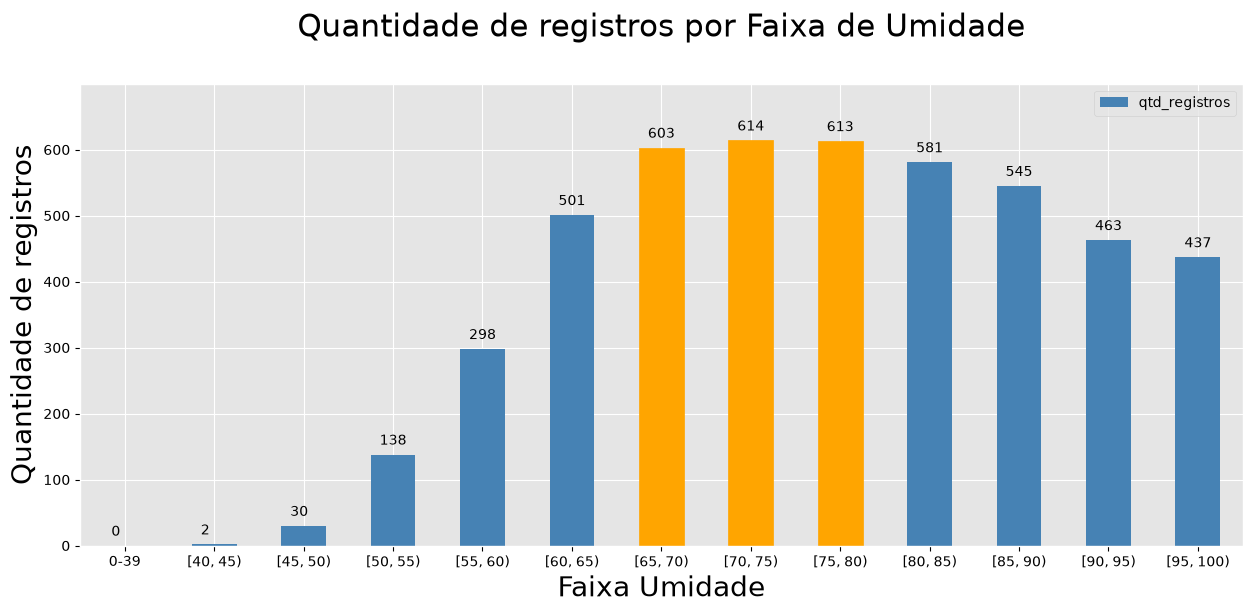

In [36]:
plt.style.use('ggplot')

#### agrupar as faixas com valor = 0 #####
qtd_grafico = qtd[qtd['qtd_registros'] > 0].copy()
qtd_grafico = pd.concat([
    pd.DataFrame({
        'faixa_umidade': ['0-39'],
        'qtd_registros': [0]
    }),
    qtd_grafico
], ignore_index=True) 


umid = qtd_grafico.set_index('faixa_umidade').plot(
    kind='bar',
    rot=0, 
    figsize=(15,6),
    color='steelblue',
    fontsize=10,
)

umid.set_title('Quantidade de registros por Faixa de Umidade\n', fontsize=22, color='black')
umid.set_ylabel('Quantidade de registros', fontsize=20, color='black')
umid.set_xlabel('Faixa Umidade', fontsize=20, color='black')
umid.set_yticks(range(0,700,100))
umid.set_ylim((0,700))

umid.tick_params(axis='x', colors='black')
umid.tick_params(axis='y', colors='black')

### colorir as 3 barras com maior valor ###
top3 = qtd_grafico['qtd_registros'].nlargest(3).index

for posicao, barra in enumerate(umid.patches):
    if posicao in top3:
        barra.set_color('orange')


for i in umid.patches:
    umid.text(
        i.get_x() + 0.1, 
        i.get_height()+15,
        i.get_height(), 
        color='black'
    )

plt.show()

## Desafio 4 - Onde concentrar o monitoramento?

A equipe precisa decidir onde concentrar seus esforços no próximo período de monitoramento. Para isso, quer identificar quais câmeras apresentam maior atividade e variedade de espécies.

**Pergunta:**

> **Quais câmeras apresentam maior quantidade de registros e maior variedade de espécies? Essas câmeras estão concentradas em alguma das três áreas do parque?**

Apresente uma recomendação baseada nos dados e explique quais informações foram consideradas para chegar à conclusão.

### •Mostrar qtd de registros por câmera

In [37]:
dt.id_camera.value_counts().reset_index()

,id_camera,count
0,CAM09,523
1,CAM12,504
2,CAM10,474
3,CAM02,471
4,CAM04,442
5,CAM08,418
6,CAM06,400
7,CAM01,394
8,CAM05,377
9,CAM07,364


### •Mostrar qtd de registros por câmera e epécie

In [38]:
resultado = (
    dt.value_counts(["id_camera", "especie"])
    .reset_index(name="Qtd")
    .sort_values(
        by=["id_camera", "Qtd"],
        ascending=[True, False]
    ).reset_index(drop=True)
)

resultado.head(30)

,id_camera,especie,Qtd
0,CAM01,Ema,80
1,CAM01,Seriema,76
2,CAM01,Lobo-guará,66
3,CAM01,Veado-campeiro,53
4,CAM01,Tamanduá-bandeira,35
5,CAM01,Tatu-canastra,32
6,CAM01,Sapo-cururu,14
7,CAM01,Quati,14
8,CAM01,Capivara,9
9,CAM01,Cervo-do-pantanal,7


### •Mostrar qtd de registros e espécies por câmera 

In [39]:
Cam = (
    dt.groupby("id_camera")
    .agg(
        Qtd_registros=("id_registro", "count"),
        Qtd_especies=("especie", "nunique")

    )
    .reset_index()
    .sort_values(by="Qtd_registros", ascending=False)
    .reset_index(drop=True)
)

Cam.head(30)

,id_camera,Qtd_registros,Qtd_especies
0,CAM09,523,12
1,CAM12,504,13
2,CAM10,474,12
3,CAM02,471,12
4,CAM04,442,12
5,CAM08,418,13
6,CAM06,400,13
7,CAM01,394,12
8,CAM05,377,13
9,CAM07,364,13


### Veredas e áreas úmidas

### •Espécies mais capturadas por câmera

In [40]:
max_esp = (
    dt.value_counts(["id_camera", "especie"])
    .reset_index(name="Qtd")
)

max_esp = (
    max_esp
    .sort_values(["id_camera", "Qtd"], ascending=[True, False])
    .groupby("id_camera")
    .first()
    .reset_index()
)

max_esp

,id_camera,especie,Qtd
0,CAM01,Ema,80
1,CAM02,Ema,100
2,CAM03,Ema,68
3,CAM04,Seriema,90
4,CAM05,Capivara,59
5,CAM06,Quati,59
6,CAM07,Quati,55
7,CAM08,Quati,65
8,CAM09,Capivara,141
9,CAM10,Capivara,137


### •Criação de uma coluna nova chamada Ambiente, para facilitar a análise de acordo ambiente que estão as câmeras.

In [41]:
dt.loc[dt['id_camera'].isin(["CAM01","CAM02","CAM03","CAM04"]),'Ambiente'] = 'Cerrado aberto'
dt.loc[dt['id_camera'].isin(["CAM05","CAM06","CAM07","CAM08"]),'Ambiente'] = 'Mata de galeria'
dt.loc[dt['id_camera'].isin(["CAM09","CAM10","CAM11","CAM12"]),'Ambiente'] = 'Veredas e áreas úmidas'

dt.head()

,id_registro,id_camera,data_hora_inicio,duracao_segundos,especie,grupo,individuos,temperatura_c,umidade_pct,Data,Hora,Periodo,Ambiente
0,1,CAM01,2026-05-01 00:04:00,25,Ema,Ave,3,19.3 °C,81.5%,2026-05-01,00:04:00,Madrugada,Cerrado aberto
1,2,CAM08,2026-05-01 00:18:00,9,Rã-manteiga,Anfíbio,3,16.6 °C,88.8%,2026-05-01,00:18:00,Madrugada,Mata de galeria
2,3,CAM08,2026-05-01 00:32:00,6,Tatu-canastra,Mamífero,1,16.5 °C,96.3%,2026-05-01,00:32:00,Madrugada,Mata de galeria
3,4,CAM12,2026-05-01 00:37:00,13,Rã-manteiga,Anfíbio,2,19.2 °C,92.1%,2026-05-01,00:37:00,Madrugada,Veredas e áreas úmidas
4,5,CAM03,2026-05-01 00:39:00,25,Tamanduá-bandeira,Mamífero,1,20.5 °C,82.6%,2026-05-01,00:39:00,Madrugada,Cerrado aberto


In [42]:
Qtd = (
    dt.value_counts(["id_camera"])
    .reset_index(name="Qtd")
    .sort_values(
        by=["Qtd"],
        ascending=[False]
    ).reset_index(drop=True)
)
Qtd

,id_camera,Qtd
0,CAM09,523
1,CAM12,504
2,CAM10,474
3,CAM02,471
4,CAM04,442
5,CAM08,418
6,CAM06,400
7,CAM01,394
8,CAM05,377
9,CAM07,364


### •Gráfico de Dispersão Ambiente VS Número de Registros

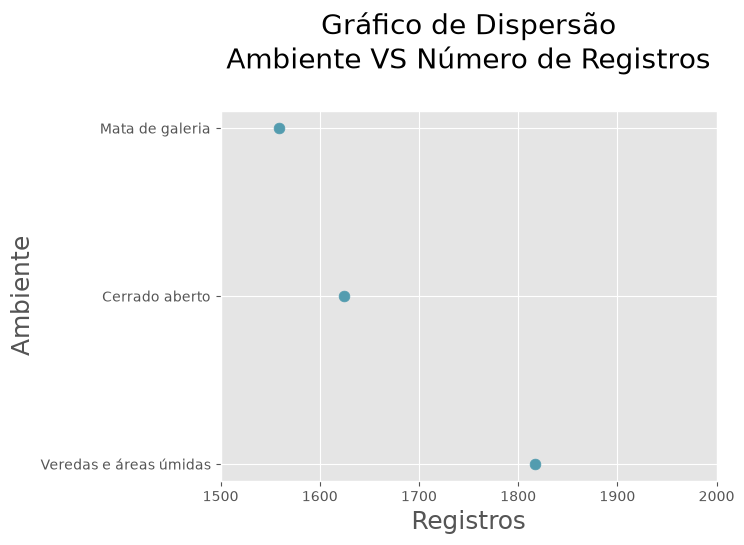

In [43]:
Qtd = (
    dt.value_counts(["Ambiente"])
    .reset_index(name="Qtd")
    .sort_values(
        by=["Qtd"],
        ascending=[False]
    ).reset_index(drop=True)
)

def scatterplot(x_data, y_data, x_label, y_label, title):

    # Create the plot object
    _, ax = plt.subplots()

    # Plot the data, set the size (s), color and transparency (alpha)
    # of the points
    ax.scatter(x_data, y_data, s = 60, color = '#539caf', alpha = 1)
    
    # Label the axes and provide a title
    ax.set_title(title,fontsize=20)
    ax.set_xlabel(x_label,fontsize=18)
    ax.set_ylabel(y_label,fontsize=18)
    ax.set_xticks(range(1500, 2001, 100))
    ax.set_xlim((1500,2000))
plt.style.use('ggplot')

# Call the function to create plot
scatterplot(x_data = Qtd['Qtd']
            , y_data = Qtd['Ambiente']
            , x_label = 'Registros'
            , y_label = 'Ambiente'
            , title = 'Gráfico de Dispersão\n' + 'Ambiente VS Número de Registros\n')

In [44]:
Qtd = (
    dt.groupby("Ambiente")
    .agg(
        Qtd=("id_registro", "count"),
        Cameras=("id_camera", lambda x: ", ".join(
            sorted(x.unique(), key=lambda cam: int(cam.replace("CAM", "")))
        ))
    )
    .reset_index()
    .sort_values(by="Qtd", ascending=False)
    .reset_index(drop=True)
)
Qtd

,Ambiente,Qtd,Cameras
0,Veredas e áreas úmidas,1817,"CAM09, CAM10, CAM11, CAM12"
1,Cerrado aberto,1624,"CAM01, CAM02, CAM03, CAM04"
2,Mata de galeria,1559,"CAM05, CAM06, CAM07, CAM08"


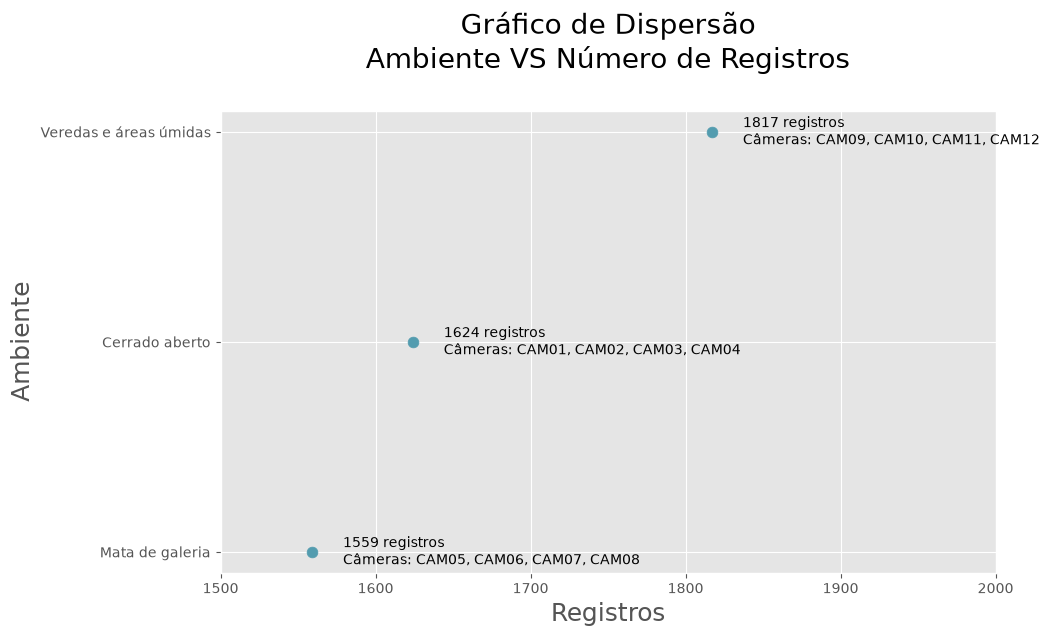

In [45]:
#Agrega a quantidade de registros e as câmeras por ambiente, ordenando pelo número de registros e Câmeras
Qtd = (
    dt.groupby("Ambiente")
    .agg(
        Qtd=("id_registro", "count"),
        Cameras=("id_camera", lambda x: ", ".join(
            sorted(x.unique(), key=lambda cam: int(cam.replace("CAM", "")))
        ))
    )
    .reset_index()
    .sort_values(by="Qtd", ascending=False)
    .reset_index(drop=True)
)
def scatterplot(x_data, y_data, cameras, x_label, y_label, title):

    _, ax = plt.subplots(figsize=(10, 6))

    ax.scatter(
        x_data,
        y_data,
        s=60,
        color='#539caf',
        alpha=1
    )

    # Valores de registros e câmeras próximo à esfera
    for x, y, cam in zip(x_data, y_data, cameras):

        ax.text(
            x + 20,
            y,
            f'{x} registros\nCâmeras: {cam}',
            va='center',
            fontsize=10
        )

    ax.set_title(title, fontsize=20)
    ax.set_xlabel(x_label, fontsize=18)
    ax.set_ylabel(y_label, fontsize=18)

    ax.set_xticks(range(1500, 2001, 100))
    ax.set_xlim((1500, 2000))

    ax.invert_yaxis()#inverte o eixo y para que o ambiente com mais registros fique no topo do gráfico

plt.style.use('ggplot')

scatterplot(
    x_data=Qtd['Qtd'],
    y_data=Qtd['Ambiente'],
    cameras=Qtd['Cameras'],
    x_label='Registros',
    y_label='Ambiente',
    title='Gráfico de Dispersão\nAmbiente VS Número de Registros\n'
)

In [46]:
Qtd = (
    dt.groupby("Ambiente")
    .agg(
        Qtd=("id_registro", "count"),
        Cameras=("id_camera", lambda x: ", ".join(
            sorted(x.unique(), key=lambda cam: int(cam.replace("CAM", "")))
        ))
    )
    .reset_index()
    .sort_values(by="Qtd", ascending=False)
    .reset_index(drop=True)
)
Qtd

,Ambiente,Qtd,Cameras
0,Veredas e áreas úmidas,1817,"CAM09, CAM10, CAM11, CAM12"
1,Cerrado aberto,1624,"CAM01, CAM02, CAM03, CAM04"
2,Mata de galeria,1559,"CAM05, CAM06, CAM07, CAM08"


## Desafio 5 - Onde procurar a onça-pintada?

Um grupo de biólogos pretende aumentar as chances de registrar uma onça-pintada no próximo período de monitoramento.

**Pergunta:**

> **Com base nos registros deste mês, em quais câmeras, áreas e períodos do dia você recomendaria concentrar o próximo monitoramento?**

Use os dados para sustentar sua recomendação.

Considere que registros de câmeras representam eventos de detecção e que a ausência de registros não significa necessariamente ausência da espécie.

### •Gráfico de Qtd de Onças por período

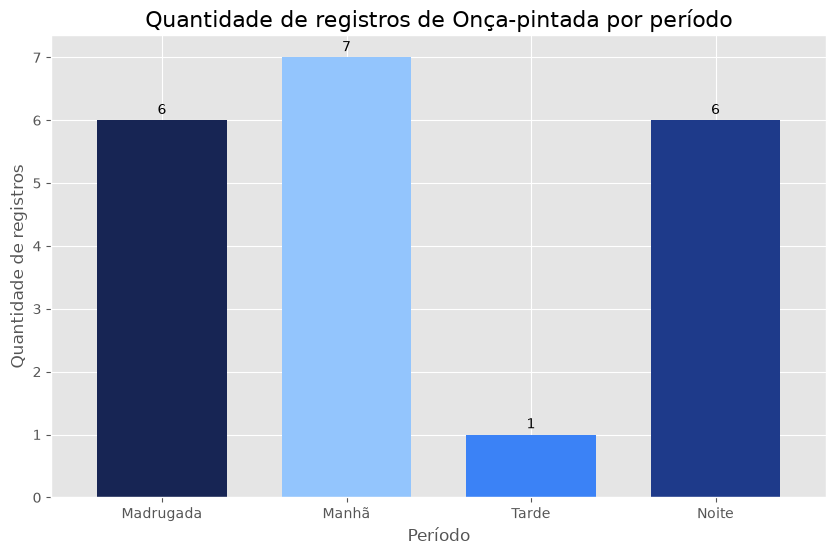

In [47]:
periodo_especie = (
    dt[dt.especie == "Onça-pintada"]
    .groupby("Periodo")
    .size()
    .reindex(["Madrugada", "Manhã", "Tarde", "Noite"])
)

ax = periodo_especie.plot(
    kind="bar",
    figsize=(10, 6),
    color=["#172554", "#93C5FD", "#3B82F6", "#1E3A8A"],
    width=0.7
)

# Valores no topo das barras
for i in ax.patches:
    ax.text(
        i.get_x() + i.get_width() / 2,
        i.get_height()+0.1 ,
        int(i.get_height()),
        ha="center",
        fontsize=10
    )

ax.set_title(
    "Quantidade de registros de Onça-pintada por período",
    fontsize=16
)

ax.set_xlabel("Período")
ax.set_ylabel("Quantidade de registros")

ax.tick_params(axis="x", rotation=0)

plt.show()

### •Gráfico de Qtd de Onças por câmera

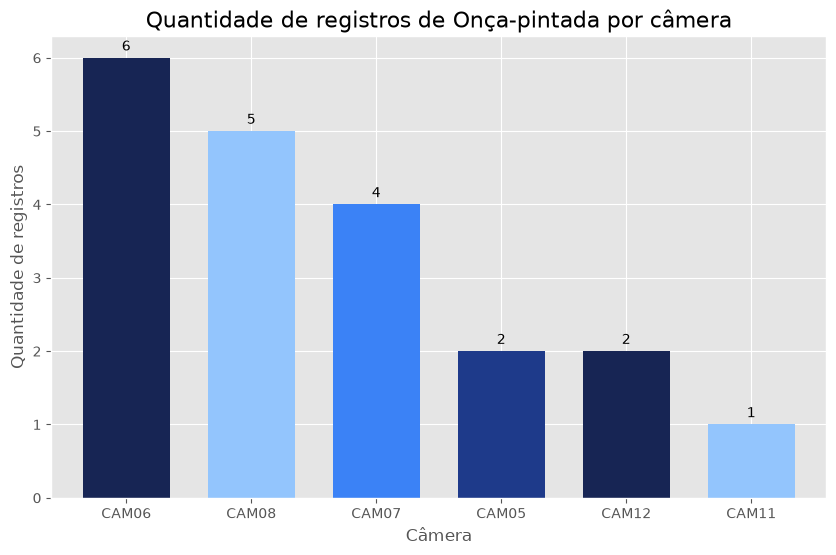

In [48]:
periodo_especie = (
    dt[dt.especie == "Onça-pintada"]
    .groupby("id_camera")
    .size()
    .sort_values(ascending=False)
)

ax = periodo_especie.plot(
    kind="bar",
    figsize=(10, 6),
    color=["#172554", "#93C5FD", "#3B82F6", "#1E3A8A"],
    width=0.7
)

# Valores no topo das barras
for i in ax.patches:
    ax.text(
        i.get_x() + i.get_width() / 2,
        i.get_height()+0.1 ,
        int(i.get_height()),
        ha="center",
        fontsize=10
    )

ax.set_title(
    "Quantidade de registros de Onça-pintada por câmera",
    fontsize=16
)

ax.set_xlabel("Câmera")
ax.set_ylabel("Quantidade de registros")

ax.tick_params(axis="x", rotation=0)

plt.show()

### •Gráfico de Qtd de Onças por ambiente

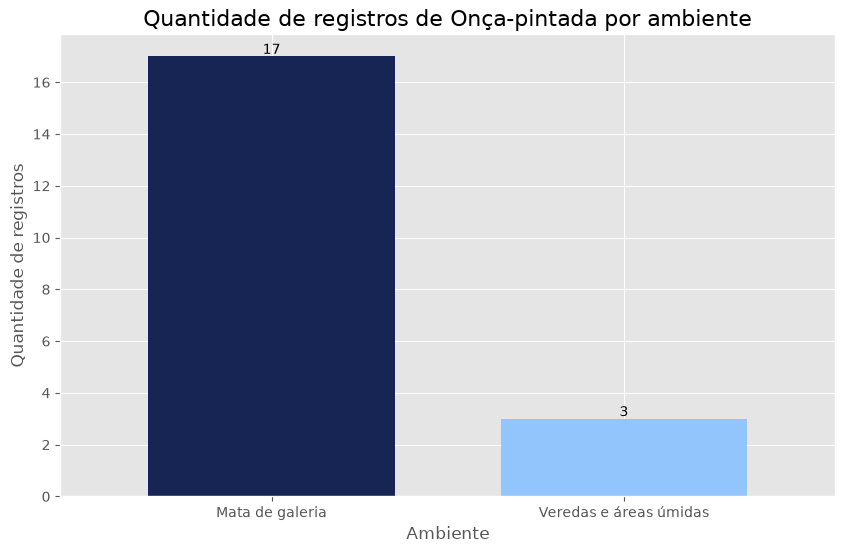

In [49]:
periodo_especie = (
    dt[dt.especie == "Onça-pintada"]
    .groupby("Ambiente")
    .size()
    .sort_values(ascending=False)
)

ax = periodo_especie.plot(
    kind="bar",
    figsize=(10, 6),
    color=["#172554", "#93C5FD", "#3B82F6", "#1E3A8A"],
    width=0.7
)

# Valores no topo das barras
for i in ax.patches:
    ax.text(
        i.get_x() + i.get_width() / 2,
        i.get_height()+0.1 ,
        int(i.get_height()),
        ha="center",
        fontsize=10
    )

ax.set_title(
    "Quantidade de registros de Onça-pintada por ambiente",
    fontsize=16
)

ax.set_xlabel("Ambiente")
ax.set_ylabel("Quantidade de registros")

ax.tick_params(axis="x", rotation=0)

plt.show()

### •Separação da coluna Hora em 3 novas colunas

In [50]:
dt['Hor'] = dt['Hora'].map(lambda hora: hora.hour   if pd.notna(hora) else np.nan)
dt['Min'] = dt['Hora'].map(lambda hora: hora.minute if pd.notna(hora) else np.nan)
dt['Seg'] = dt['Hora'].map(lambda hora: hora.second if pd.notna(hora) else np.nan)

dt.head()

,id_registro,id_camera,data_hora_inicio,duracao_segundos,especie,grupo,individuos,temperatura_c,umidade_pct,Data,Hora,Periodo,Ambiente,Hor,Min,Seg
0,1,CAM01,2026-05-01 00:04:00,25,Ema,Ave,3,19.3 °C,81.5%,2026-05-01,00:04:00,Madrugada,Cerrado aberto,0,4,0
1,2,CAM08,2026-05-01 00:18:00,9,Rã-manteiga,Anfíbio,3,16.6 °C,88.8%,2026-05-01,00:18:00,Madrugada,Mata de galeria,0,18,0
2,3,CAM08,2026-05-01 00:32:00,6,Tatu-canastra,Mamífero,1,16.5 °C,96.3%,2026-05-01,00:32:00,Madrugada,Mata de galeria,0,32,0
3,4,CAM12,2026-05-01 00:37:00,13,Rã-manteiga,Anfíbio,2,19.2 °C,92.1%,2026-05-01,00:37:00,Madrugada,Veredas e áreas úmidas,0,37,0
4,5,CAM03,2026-05-01 00:39:00,25,Tamanduá-bandeira,Mamífero,1,20.5 °C,82.6%,2026-05-01,00:39:00,Madrugada,Cerrado aberto,0,39,0


### •Gráfico de Qtd de Onças por hora

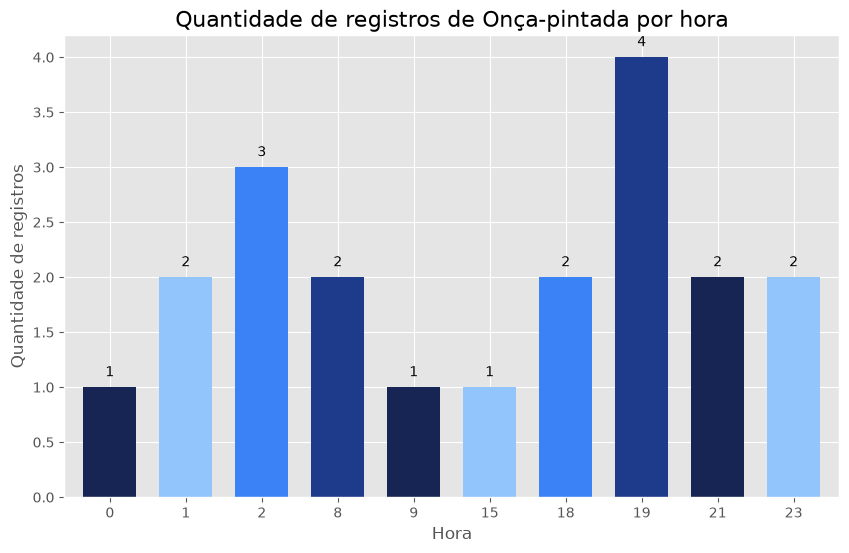

In [51]:
periodo_especie = (
    dt[dt.especie == "Onça-pintada"]
    .groupby("Hor")
    .size()
)

ax = periodo_especie.plot(
    kind="bar",
    figsize=(10, 6),
    color=["#172554", "#93C5FD", "#3B82F6", "#1E3A8A"],
    width=0.7
)

# Valores no topo das barras
for i in ax.patches:
    ax.text(
        i.get_x() + i.get_width() / 2,
        i.get_height()+0.1 ,
        int(i.get_height()),
        ha="center",
        fontsize=10
    )

ax.set_title(
    "Quantidade de registros de Onça-pintada por hora",
    fontsize=16
)

ax.set_xlabel("Hora")
ax.set_ylabel("Quantidade de registros")

ax.tick_params(axis="x", rotation=0)

plt.show()

# Conclusão Desafio 5
### •De acordo com as análises realizadas, podemos concluir que a espécie "Onça-pintada" apresenta uma maior quantidade de registros durante o período da manhã, madrugada e noite, com destaque para o horário das 19 às 20 e para as câmeras 5,6,7 e 8 localizadas em ambientes de Mata de Galeria.


In [52]:
QtdHr = (
    dt["Hor"]
    .value_counts()
    #.rename_axis("Hora")
    .reset_index(name="Qtd")
    .sort_values(by="Hor", ascending=True)
    #.reset_index(drop=False)
)
#Qtd.columns = ["Hora", "Qtd"]
display(QtdHr.style.hide(axis="index"))



Hor,Qtd
0,176
1,189
2,159
3,150
4,170
5,243
6,293
7,282
8,257
9,197


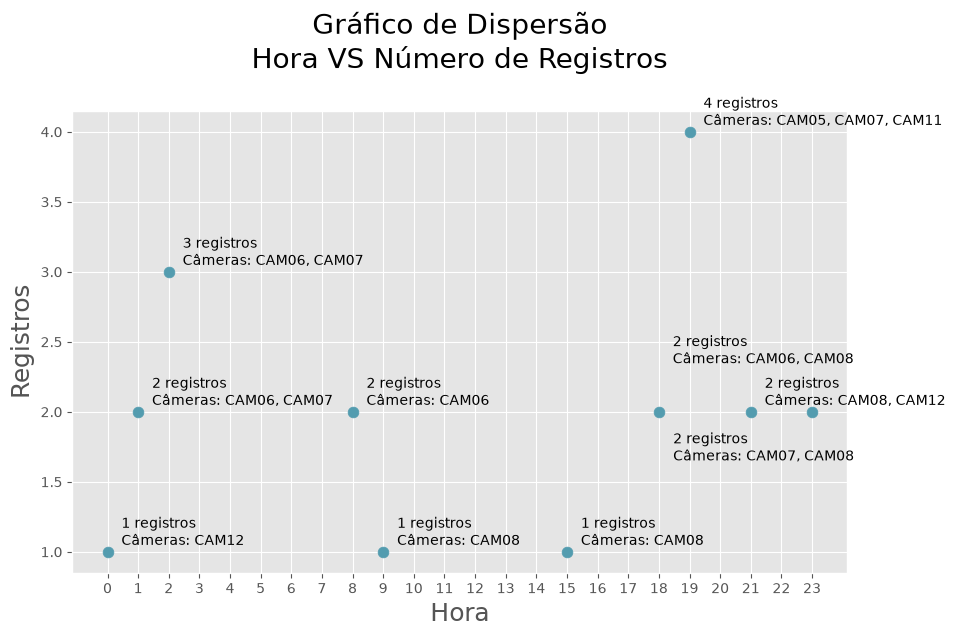

In [53]:
#%pip install adjustText
from adjustText import adjust_text
#Agrega a quantidade de registros e as câmeras por Hora, ordenando pelo número de registros e Câmeras
Qtd = (
    dt[dt["especie"] == "Onça-pintada"]
    .groupby("Hor")
    .agg(
        Qtd=("id_registro", "count"),
        Cameras=(
            "id_camera",
            lambda x: ", ".join(
                sorted(
                    x.unique(),
                    key=lambda cam: int(cam.replace("CAM", ""))
                )
            )
        )
    )
    .reset_index()
    .sort_values(by="Qtd", ascending=False)
    .reset_index(drop=True)
)


#Agrega a quantidade de registros e as câmeras por ambiente, ordenando pelo número de registros e Câmeras

def scatterplot(x_data, y_data, cameras, x_label, y_label, title):

    _, ax = plt.subplots(figsize=(10, 6))

    ax.scatter(
        x_data,
        y_data,
        s=60,
        color='#539caf',
        alpha=1
    )

    # Valores de registros e câmeras próximo à esfera
    for x, y, cam in zip(x_data, y_data, cameras):

        if x == 18:
            pos = (10, 35)
        elif x == 22:
            pos = (-120, 35)
        elif x == 23:
            pos = (-100, -35)
        else:
            pos = (10, 5)

        ax.annotate(
            f'{y} registros\nCâmeras: {cam}',
            xy=(x, y),
            xytext=pos,
            textcoords='offset points',
            fontsize=10
        )

    ax.set_title(title, fontsize=20)
    ax.set_xlabel(x_label, fontsize=18)
    ax.set_ylabel(y_label, fontsize=18)

    ax.set_xticks(range(0, 24, 1))
    #ax.set_xlim((0, 6))

    #ax.invert_yaxis()#inverte o eixo y para que o ambiente com mais registros fique no topo do gráfico

plt.style.use('ggplot')

scatterplot(
    x_data=Qtd['Hor'],
    y_data=Qtd['Qtd'],
    cameras=Qtd['Cameras'],
    x_label='Hora',
    y_label='Registros',
    title='Gráfico de Dispersão\nHora VS Número de Registros\n'
)

In [54]:
periodo_especie = (
    dt[dt["especie"] == "Onça-pintada"]
    .groupby("Hor")
    .agg(
        Qtd=("id_registro", "count"),
        Cameras=(
            "id_camera",
            lambda x: ", ".join(
                sorted(
                    x.unique(),
                    key=lambda cam: int(cam.replace("CAM", ""))
                )
            )
        )
    )
    .reset_index()
    .sort_values(by="Qtd", ascending=False)
    .reset_index(drop=True)
)

periodo_especie

,Hor,Qtd,Cameras
0,19,4,"CAM05, CAM07, CAM11"
1,2,3,"CAM06, CAM07"
2,21,2,"CAM08, CAM12"
3,1,2,"CAM06, CAM07"
4,18,2,"CAM06, CAM08"
5,8,2,CAM06
6,23,2,"CAM07, CAM08"
7,0,1,CAM12
8,15,1,CAM08
9,9,1,CAM08


In [55]:
QtdHr = (
    dt["Hor"]
    .value_counts()
    #.rename_axis("Hora")
    .reset_index(name="Qtd")
    .sort_values(by="Hor", ascending=True)
    #.reset_index(drop=False)
)
#Qtd.columns = ["Hora", "Qtd"]
display(QtdHr.style.hide(axis="index"))



Hor,Qtd
0,176
1,189
2,159
3,150
4,170
5,243
6,293
7,282
8,257
9,197


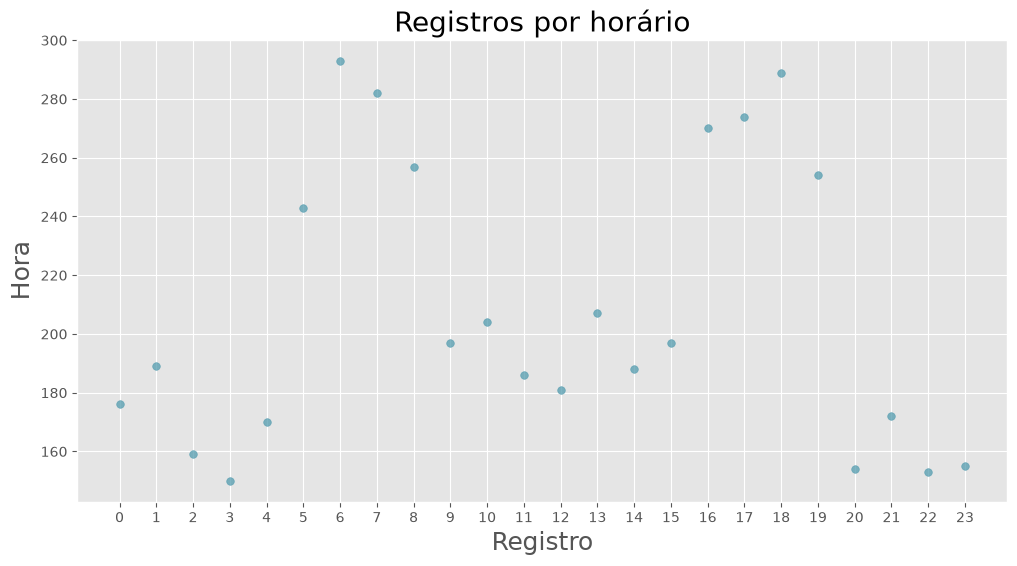

In [56]:
def scatterplot(x_data, y_data, x_label, y_label, title):

    _, ax = plt.subplots(figsize=(12, 6))

    ax.scatter(
        x_data,
        y_data,
        s=30,
        color='#539caf',
        alpha=0.75
    )

    ax.set_title(title, fontsize=20)
    ax.set_xlabel(x_label, fontsize=18)
    ax.set_ylabel(y_label, fontsize=18)

    # ax.set_xticks(range(0, 24, 1))
    # ax.set_ylim((0,350))

plt.style.use('ggplot')



scatterplot(
    x_data=QtdHr["Hor"].astype(str),
    y_data=QtdHr["Qtd"],
    x_label="Registro",
    y_label="Hora",
    title="Registros por horário"
)

In [57]:
QtdHrEsp = (
    dt.groupby(["Hor"])
    .agg(
        Qtd_registros=("id_registro", "count"),
        Qtd_especies=("especie", "nunique")
    )
    #.rename_axis("Hora")
    .reset_index()
    .sort_values(by="Hor", ascending=True)
    #.reset_index(drop=False)
)
#Qtd.columns = ["Hora", "Qtd"]
display(QtdHrEsp.style.hide(axis="index"))




Hor,Qtd_registros,Qtd_especies
0,176,13
1,189,13
2,159,12
3,150,12
4,170,12
5,243,12
6,293,12
7,282,12
8,257,13
9,197,13


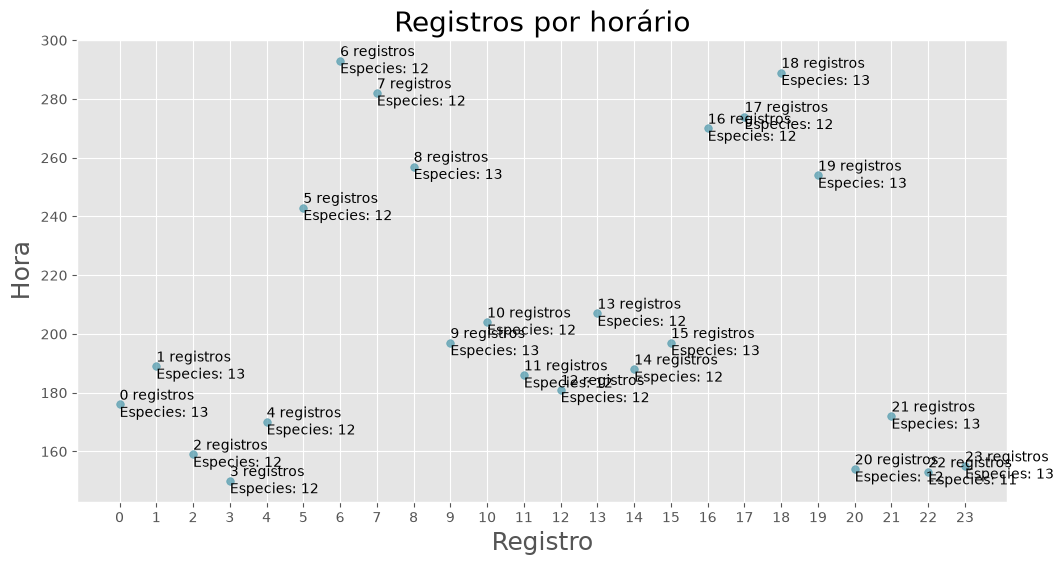

In [58]:
def scatterplot(x_data, y_data, x_label, y_label, title,especies):

    _, ax = plt.subplots(figsize=(12, 6))

    ax.scatter(
        x_data,
        y_data,
        s=30,
        color='#539caf',
        alpha=0.75
    )

    # Valores de registros e câmeras próximo à esfera
    for x, y, esp in zip(x_data, y_data, especies):

        ax.text(
            x ,
            y,
            f'{x} registros\nEspecies: {esp}',
            va='center',
            fontsize=10
        )


    ax.set_title(title, fontsize=20)
    ax.set_xlabel(x_label, fontsize=18)
    ax.set_ylabel(y_label, fontsize=18)

    # ax.set_xticks(range(0, 24, 1))
    # ax.set_ylim((0,350))

plt.style.use('ggplot')



scatterplot(
    x_data=QtdHrEsp["Hor"].astype(str),
    y_data=QtdHrEsp["Qtd_registros"],
    especies=QtdHrEsp["Qtd_especies"],
    x_label="Registro",
    y_label="Hora",
    title="Registros por horário"
)

# ⭐ Desafios bônus

Os desafios abaixo são opcionais e podem ser utilizados para aprofundar a investigação.

## Bônus 1 - O que aconteceu com os sensores?

Durante a consolidação dos dados, a equipe percebeu que algumas câmeras deixaram de registrar informações de temperatura e umidade em determinados momentos, embora continuassem registrando os animais normalmente.

**Pergunta:**

> **Quais câmeras foram afetadas e em que período os problemas ocorreram? O que pode ter causado esse comportamento e como você trataria os valores faltantes antes de utilizar essas variáveis em uma análise?**

In [59]:
#converter a coluna de temperatura para float, removendo o caractere "°C"
temperatura = (
    dt["temperatura_c"]
    .str.replace("°C", "")
    .astype(float)
)

display(temperatura.mean())
display(temperatura.std())




np.float64(22.997601514832738)

np.float64(4.261491511504389)

In [60]:
dt_nulos = (
    dt[
        dt.isnull()
       .any(axis=1)]
       .reset_index(drop=True)
)
# dt_nulos = dt[
#     dt["temperatura_c"].isna() 
#     #dt["umidade_pct"].isna()
#     ].reset_index(drop=True)

Data = dt_nulos["Data"].value_counts().reset_index(name="Qtd").sort_values("Data").reset_index(drop=True)
DataHora = dt_nulos[["Data","Hor"]].value_counts().reset_index(name="Qtd").sort_values(["Data","Hor"]).reset_index(drop=True)
Hora = dt_nulos["Hor"].value_counts().reset_index(name="Qtd").sort_values("Hor").reset_index(drop=True)
Cam = dt_nulos["id_camera"].value_counts().reset_index(name="Qtd").sort_values("id_camera").reset_index(drop=True)

CamAgrp = (
    dt_nulos.groupby("Data")
        .agg(
            Qtd=("id_registro", "count"),
            Cameras=("id_camera", lambda x: ", ".join(
                sorted(x.unique(), key=lambda cam: int(cam.replace("CAM", "")))
            ))
        )
)
CamAgrpTemp = (
    dt[
        dt["temperatura_c"].isna()
    ]
    .groupby("Data")
    .agg(
        Qtd=("id_registro", "count"),
        Cameras=("id_camera", lambda x: ", ".join(
            sorted(
                x.unique(),
                key=lambda cam: int(cam.replace("CAM", ""))
            )
        ))
    )
)
CamAgrpUmid = (
    dt[
        dt["umidade_pct"].isna()
    ]
    .groupby("Data")
    .agg(
        Qtd=("id_registro", "count"),
        Cameras=("id_camera", lambda x: ", ".join(
            sorted(
                x.unique(),
                key=lambda cam: int(cam.replace("CAM", ""))
            )
        ))
    )
)

print("Total de registros nulos:(Temperatura ou Umidade)", Cam["Qtd"].sum())
display("Data com registros nulos por câmera:", Cam)
display("Registros nulos por data:", Data)
display("Câmeras paradas na data:", CamAgrp)
display("Data com registros nulos na temperatura:", CamAgrpTemp)
display("Data com registros nulos na umidade:", CamAgrpUmid)


Total de registros nulos:(Temperatura ou Umidade) 352


'Data com registros nulos por câmera:'

,id_camera,Qtd
0,CAM04,177
1,CAM07,105
2,CAM11,70


'Registros nulos por data:'

,Data,Qtd
0,2026-05-18,15
1,2026-05-19,15
2,2026-05-20,14
3,2026-05-21,14
4,2026-05-22,23
5,2026-05-23,19
6,2026-05-24,28
7,2026-05-25,32
8,2026-05-26,41
9,2026-05-27,45


...

,Qtd,Cameras
Data,,
2026-05-18,15,CAM04
2026-05-19,15,CAM04
2026-05-20,14,CAM04
2026-05-21,14,CAM04
2026-05-22,23,"CAM04, CAM07"
2026-05-23,19,"CAM04, CAM07"
2026-05-24,28,"CAM04, CAM07"
2026-05-25,32,"CAM04, CAM07, CAM11"
2026-05-26,41,"CAM04, CAM07, CAM11"


'Data com registros nulos na temperatura:'

,Qtd,Cameras
Data,,
2026-05-18,15,CAM04
2026-05-19,15,CAM04
2026-05-20,14,CAM04
2026-05-21,14,CAM04
2026-05-22,12,CAM04
2026-05-23,9,CAM04
2026-05-24,9,CAM04
2026-05-25,18,"CAM04, CAM11"
2026-05-26,29,"CAM04, CAM11"


'Data com registros nulos na umidade:'

,Qtd,Cameras
Data,,
2026-05-22,11,CAM07
2026-05-23,10,CAM07
2026-05-24,19,CAM07
2026-05-25,24,"CAM07, CAM11"
2026-05-26,23,"CAM07, CAM11"
2026-05-27,26,"CAM07, CAM11"
2026-05-28,19,"CAM07, CAM11"
2026-05-29,21,"CAM07, CAM11"
2026-05-30,22,"CAM07, CAM11"


In [61]:
dt["Data"] = pd.to_datetime(dt["Data"])
dt.describe()

,id_registro,duracao_segundos,individuos,Data,Hor,Min,Seg
count,5000.000000,5000.000000,5000.00000,5000,5000.00000,5000.000000,5000.0
mean,2500.500000,26.706000,2.86540,2026-05-15 10:37:20.640000,11.51560,29.301800,0.0
min,1.000000,3.000000,1.00000,2026-05-01 00:00:00,0.00000,0.000000,0.0
25%,1250.750000,14.000000,1.00000,2026-05-08 00:00:00,6.00000,14.000000,0.0
50%,2500.500000,23.000000,2.00000,2026-05-16 00:00:00,11.00000,29.000000,0.0
75%,3750.250000,36.000000,4.00000,2026-05-23 00:00:00,17.00000,44.000000,0.0
max,5000.000000,167.000000,14.00000,2026-05-30 00:00:00,23.00000,59.000000,0.0
std,1443.520003,17.760401,1.99371,NaN,6.58787,17.479057,0.0


In [62]:
dt.head()

,id_registro,id_camera,data_hora_inicio,duracao_segundos,especie,grupo,individuos,temperatura_c,umidade_pct,Data,Hora,Periodo,Ambiente,Hor,Min,Seg
0,1,CAM01,2026-05-01 00:04:00,25,Ema,Ave,3,19.3 °C,81.5%,2026-05-01,00:04:00,Madrugada,Cerrado aberto,0,4,0
1,2,CAM08,2026-05-01 00:18:00,9,Rã-manteiga,Anfíbio,3,16.6 °C,88.8%,2026-05-01,00:18:00,Madrugada,Mata de galeria,0,18,0
2,3,CAM08,2026-05-01 00:32:00,6,Tatu-canastra,Mamífero,1,16.5 °C,96.3%,2026-05-01,00:32:00,Madrugada,Mata de galeria,0,32,0
3,4,CAM12,2026-05-01 00:37:00,13,Rã-manteiga,Anfíbio,2,19.2 °C,92.1%,2026-05-01,00:37:00,Madrugada,Veredas e áreas úmidas,0,37,0
4,5,CAM03,2026-05-01 00:39:00,25,Tamanduá-bandeira,Mamífero,1,20.5 °C,82.6%,2026-05-01,00:39:00,Madrugada,Cerrado aberto,0,39,0


In [63]:
def Converte_Num(temp_str, unidade):
    if pd.isnull(temp_str):
        return np.nan
    else:
        return float(temp_str.replace(f"{unidade}", ""))



In [64]:
CamAgrpTempe = (
    dt_nulos.groupby("Data")
    .agg(
        Qtd=("id_registro", "count"),
        Cameras=(
            "id_camera",
            lambda x: ", ".join(
                sorted(#ordenar dentro do agrupamento as câmeras por número, e não por ordem alfabética)
                    x.dropna().unique(),
                    key=lambda cam: int(cam.replace("CAM", ""))
                )
            )
        ),
        Temperatura=(
            "temperatura_c",
            #lambda x: pd.to_numeric(x.astype("string").str.replace("°C", "", regex=False),errors="coerce").mean()
            lambda x: x.map(Converte_Num, unidade="°C").mean()
        ),
        Umidade=(
            "umidade_pct",
            #lambda x: pd.to_numeric(x.astype("string").str.replace("%", "", regex=False),errors="coerce").mean()
            lambda x: x.map(Converte_Num, unidade="%").mean()
        )
    )
)

CamAgrpTempe




,Qtd,Cameras,Temperatura,Umidade
Data,,,,
2026-05-18,15,CAM04,NaN,74.280000
2026-05-19,15,CAM04,NaN,64.153333
2026-05-20,14,CAM04,NaN,69.350000
2026-05-21,14,CAM04,NaN,66.621429
2026-05-22,23,"CAM04, CAM07",21.227273,66.425000
2026-05-23,19,"CAM04, CAM07",23.880000,65.077778
2026-05-24,28,"CAM04, CAM07",20.700000,68.688889
2026-05-25,32,"CAM04, CAM07, CAM11",22.335714,70.375000
2026-05-26,41,"CAM04, CAM07, CAM11",22.941667,72.188889


In [65]:
CamAgrpTemp = (
    dt[
        dt["temperatura_c"].isna()
    ]
    .groupby("Data")
    .agg(
        Qtd=("id_registro", "count"),
        Cameras5 = ("id_camera","unique")
    )
)
CamAgrpTemp

,Qtd,Cameras5
Data,,
2026-05-18,15,[CAM04]
2026-05-19,15,[CAM04]
2026-05-20,14,[CAM04]
2026-05-21,14,[CAM04]
2026-05-22,12,[CAM04]
2026-05-23,9,[CAM04]
2026-05-24,9,[CAM04]
2026-05-25,18,"[CAM04, CAM11]"
2026-05-26,29,"[CAM04, CAM11]"


In [66]:
dt_nulos = dt[
    dt["temperatura_c"].isna() &
    dt["umidade_pct"].isna()
    ].reset_index(drop=True)
dt_nulos.head(10)

,id_registro,id_camera,data_hora_inicio,duracao_segundos,especie,grupo,individuos,temperatura_c,umidade_pct,Data,Hora,Periodo,Ambiente,Hor,Min,Seg
0,4063,CAM11,2026-05-25 07:30:00,11,Sapo-cururu,Anfíbio,5,NaN,NaN,2026-05-25,07:30:00,Manhã,Veredas e áreas úmidas,7,30,0
1,4085,CAM11,2026-05-25 10:12:00,4,Capivara,Mamífero,8,NaN,NaN,2026-05-25,10:12:00,Manhã,Veredas e áreas úmidas,10,12,0
2,4087,CAM11,2026-05-25 10:20:00,48,Capivara,Mamífero,4,NaN,NaN,2026-05-25,10:20:00,Manhã,Veredas e áreas úmidas,10,20,0
3,4105,CAM11,2026-05-25 13:33:00,22,Sapo-cururu,Anfíbio,2,NaN,NaN,2026-05-25,13:33:00,Tarde,Veredas e áreas úmidas,13,33,0
4,4110,CAM11,2026-05-25 14:04:00,100,Ema,Ave,5,NaN,NaN,2026-05-25,14:04:00,Tarde,Veredas e áreas úmidas,14,4,0
5,4155,CAM11,2026-05-25 19:40:00,11,Onça-pintada,Mamífero,1,NaN,NaN,2026-05-25,19:40:00,Noite,Veredas e áreas úmidas,19,40,0
6,4159,CAM11,2026-05-25 20:25:00,20,Capivara,Mamífero,5,NaN,NaN,2026-05-25,20:25:00,Noite,Veredas e áreas úmidas,20,25,0
7,4161,CAM11,2026-05-25 20:43:00,20,Perereca-verde,Anfíbio,2,NaN,NaN,2026-05-25,20:43:00,Noite,Veredas e áreas úmidas,20,43,0
8,4172,CAM11,2026-05-25 22:37:00,8,Sapo-cururu,Anfíbio,2,NaN,NaN,2026-05-25,22:37:00,Noite,Veredas e áreas úmidas,22,37,0
9,4175,CAM11,2026-05-25 23:18:00,18,Perereca-verde,Anfíbio,1,NaN,NaN,2026-05-25,23:18:00,Manhã,Veredas e áreas úmidas,23,18,0


In [67]:

df_original = dt.copy()  # Cria uma cópia do DataFrame original antes de preencher os valores nulos

df_original.head()
#df = df_original.copy() #para voltar ao df original, caso queira fazer novas análises sem os valores nulos

,id_registro,id_camera,data_hora_inicio,duracao_segundos,especie,grupo,individuos,temperatura_c,umidade_pct,Data,Hora,Periodo,Ambiente,Hor,Min,Seg
0,1,CAM01,2026-05-01 00:04:00,25,Ema,Ave,3,19.3 °C,81.5%,2026-05-01,00:04:00,Madrugada,Cerrado aberto,0,4,0
1,2,CAM08,2026-05-01 00:18:00,9,Rã-manteiga,Anfíbio,3,16.6 °C,88.8%,2026-05-01,00:18:00,Madrugada,Mata de galeria,0,18,0
2,3,CAM08,2026-05-01 00:32:00,6,Tatu-canastra,Mamífero,1,16.5 °C,96.3%,2026-05-01,00:32:00,Madrugada,Mata de galeria,0,32,0
3,4,CAM12,2026-05-01 00:37:00,13,Rã-manteiga,Anfíbio,2,19.2 °C,92.1%,2026-05-01,00:37:00,Madrugada,Veredas e áreas úmidas,0,37,0
4,5,CAM03,2026-05-01 00:39:00,25,Tamanduá-bandeira,Mamífero,1,20.5 °C,82.6%,2026-05-01,00:39:00,Madrugada,Cerrado aberto,0,39,0


In [68]:
# temperatura_num = dt["temperatura_c"].map(Converte_Num,unidade="°C")
# Preenche_Temp = dt["temperatura_c"] = dt["temperatura_c"].fillna(temperatura_num.mean(),inplace=True)#inplace=True para alterar o df original
# dt_nulos.head(10)
#Preenche_Temp

In [75]:
dt[dt["id_registro"] == 4032]


,id_registro,id_camera,data_hora_inicio,duracao_segundos,especie,grupo,individuos,temperatura_c,umidade_pct,Data,Hora,Periodo,Ambiente,Hor,Min,Seg
4031,4032,CAM04,2026-05-25 03:30:00,24,Sapo-cururu,Anfíbio,1,24.7 °C,78.3%,2026-05-25,03:30:00,Madrugada,Cerrado aberto,3,30,0


In [70]:
temperatura_num = dt["temperatura_c"].map(Converte_Num,unidade="°C")

MediaCam04 = temperatura_num[dt["id_camera"] == "CAM04"].mean()
MediaCam07 = temperatura_num[dt["id_camera"] == "CAM07"].mean()
MediaCam11 = temperatura_num[dt["id_camera"] == "CAM11"].mean()
#print(f"Temperatura média da CAM11: {MediaCam11:.1f} °C")
Preencher11 = f"{MediaCam11:.1f} °C"
Preencher11

'21.9 °C'

In [84]:
temperatura_num = dt["temperatura_c"].map(
    Converte_Num,
    unidade="°C"
)

media_cam04 = temperatura_num[dt["id_camera"] == "CAM04"].mean()
media_cam07 = temperatura_num[dt["id_camera"] == "CAM07"].mean()
media_cam11 = temperatura_num[dt["id_camera"] == "CAM11"].mean()

dt.loc[
    (dt["id_camera"] == "CAM04") & dt["temperatura_c"].isna(),
    "temperatura_c"
] = f"{media_cam04:.1f} °C"

dt.loc[
    (dt["id_camera"] == "CAM07") & dt["temperatura_c"].isna(),
    "temperatura_c"
] = f"{media_cam07:.1f} °C"

dt.loc[
    (dt["id_camera"] == "CAM11") & dt["temperatura_c"].isna(),
    "temperatura_c"
] = f"{media_cam11:.1f} °C"

tempe = dt.loc[
    ((dt["id_camera"] == "CAM04") | (dt["id_camera"] == "CAM07") | (dt["id_camera"] == "CAM11")) & (dt["temperatura_c"].isna())
].reset_index()

tempe.head()


,index,id_registro,id_camera,data_hora_inicio,duracao_segundos,especie,grupo,individuos,temperatura_c,umidade_pct,Data,Hora,Periodo,Ambiente,Hor,Min,Seg


In [90]:
umidade_num = dt["umidade_pct"].map(
    Converte_Num,
    unidade="%"
)

media_cam04 = umidade_num[dt["id_camera"] == "CAM04"].mean()
media_cam07 = umidade_num[dt["id_camera"] == "CAM07"].mean()
media_cam11 = umidade_num[dt["id_camera"] == "CAM11"].mean()

dt.loc[
    (dt["id_camera"] == "CAM04") & dt["umidade_pct"].isna(),
    "umidade_pct"
] = f"{media_cam04:.1f} %"

dt.loc[
    (dt["id_camera"] == "CAM07") & dt["umidade_pct"].isna(),
    "umidade_pct"
] = f"{media_cam07:.1f} %"

dt.loc[
    (dt["id_camera"] == "CAM11") & dt["umidade_pct"].isna(),
    "umidade_pct"
] = f"{media_cam11:.1f} %"

umid = dt.loc[
    ((dt["id_camera"] == "CAM04") | (dt["id_camera"] == "CAM07") | (dt["id_camera"] == "CAM11")) & (dt["umidade_pct"].isna())
].reset_index()

umid.head()


,index,id_registro,id_camera,data_hora_inicio,duracao_segundos,especie,grupo,individuos,temperatura_c,umidade_pct,Data,Hora,Periodo,Ambiente,Hor,Min,Seg


In [ ]:
# temperatura_num = dt["temperatura_c"].map(Converte_Num,unidade="°C")
# Preenche_Temp = dt["temperatura_c"] = dt[dt["id_camera"]=="CAM11"].fillna(Preencher11,inplace=True)#inplace=True para alterar o df original
# display(dt_nulos.head(10))
# display(Preenche_Temp)


## Bônus 2 - Quanto tempo duram os registros?

A equipe quer entender se a duração dos eventos registrados varia entre as espécies e se esse comportamento pode ajudar na interpretação dos registros.

**Pergunta:**

> **Quais espécies apresentam os registros mais longos e mais curtos? Como a duração dos registros se distribui entre as espécies e o que essa diferença pode indicar?**